# Convolution và pooling

Đưa ảnh vào MLP phải trải mọi điểm ảnh thành một vector dài. Cách đó có hai vấn đề: số trọng số tăng rất nhanh khi ảnh lớn, và một nét ở góc trái với cùng nét ấy ở giữa ảnh được học như hai thứ khác nhau. Convolution dùng một bộ lọc nhỏ, ví dụ 3×3, trượt qua mọi vị trí của ảnh với cùng một bộ trọng số. Bài này học convolution, padding, stride và pooling trên ví dụ dò nét dọc, nét ngang tính được bằng tay.

> **Mục tiêu**
>
> - Tính convolution bằng tay và so với PyTorch.
> - Tính kích thước đầu ra theo kernel, padding, stride, dilation.
> - Phân biệt convolution và pooling.
> - Tính receptive field của nhiều lớp.

## Một bộ dò đi qua nhiều vị trí

Ảnh xám là bảng số $H\times W$, thường biểu diễn cường độ sáng. Ảnh màu có thêm ba kênh RGB. Các điểm cạnh nhau có quan hệ: cạnh của viên phấn thường kéo dài qua nhiều ô lân cận. Ta vì vậy đọc một cửa sổ nhỏ trước khi đọc cả ảnh. Mỗi ô của lưới gọi là một điểm ảnh (pixel); ảnh xám có một kênh, mỗi pixel một số từ 0 (đen) tới 255 (trắng).



Kernel (bộ lọc) là bảng trọng số $K$. Tại mỗi vị trí, nhân từng ô trong cửa sổ với ô tương ứng của $K$, rồi cộng. Với một kênh, stride 1, chưa có padding và bias:

$$Y_{i,j}=\sum_{u=0}^{k_h-1}\sum_{v=0}^{k_w-1}X_{i+u,j+v}K_{u,v}.$$

$i,j$ chỉ vị trí trên bảng kết quả; $u,v$ chỉ vị trí bên trong kernel. Tổng ở đây là tích vô hướng của hai bảng khi trải thành vector. Nếu đã học linear regression, ta đang dùng một mô hình tuyến tính nhỏ trên từng cửa sổ, và mọi cửa sổ dùng **chung trọng số**.

Trong toán học, convolution lật kernel $180^\circ$ trước khi nhân; phép nhân thẳng không lật gọi là cross-correlation. `Conv2d` của PyTorch làm cross-correlation, nhưng ngành học sâu vẫn gọi nó là convolution. Khi kernel được học, khác biệt này không quan trọng: mạng sẽ học luôn bản đã lật. Nó chỉ quan trọng khi đề cho sẵn kernel và hỏi kết quả; khi đó tính theo cách không lật như PyTorch.

Dùng chung trọng số còn quyết định số tham số. Nếu mỗi vị trí đầu ra có kernel riêng, một ảnh xám cho đầu ra $28\times28$ cần 784 bộ trọng số; dùng chung thì chỉ một bộ, và bộ ấy học từ mọi vị trí cùng lúc. So với nối thẳng mọi pixel vào lớp kết nối đầy đủ, khác biệt rất lớn: ảnh $224 \times 224 \times 3$ vào 1000 neuron đã cần khoảng 150 triệu trọng số.

**Hỏi nhanh.** Hàng ảnh `[0, 0, 5, 5]` có một cạnh chuyển từ tối sang sáng. Kernel `[-1, 1]`, stride 1, không padding. `Conv2d` của PyTorch cho ra kết quả nào?

- A. `[0, 5, 0]`
- B. `[0, -5, 0]`
- C. `[0, 0, 5]`
- D. `[0, 5, 0, 0]`

<details><summary>Đáp án</summary>

A. `[0, 5, 0]`

Cửa sổ thứ hai là `[0, 5]`, nhân thẳng với `[-1, 1]` được 5: kernel này cho số dương ở cạnh tối sang sáng. `[0, -5, 0]` là kết quả khi lật kernel thành `[1, -1]` như convolution trong toán. `[0, 0, 5]` là gán kết quả vào ô bên phải của cửa sổ, trong khi ô đầu ra thứ $i$ ứng với cửa sổ bắt đầu ở $i$. Không có padding thì đầu ra ngắn hơn đầu vào một ô, nên không thể có bốn số.

</details>

**Hỏi nhanh.** Ảnh xám $64\times 64$, kernel $3\times 3$, không padding, stride 1, đầu ra $62\times 62$. Nếu mỗi vị trí đầu ra có một kernel riêng thay vì dùng chung, lớp này cần bao nhiêu trọng số, bỏ qua bias?

- A. 9
- B. 3844
- C. 34 596
- D. 36 864

<details><summary>Đáp án</summary>

C. 34 596

Có $62\cdot 62 = 3844$ vị trí đầu ra, mỗi vị trí một kernel 9 số, nên cần $3844\cdot 9 = 34\,596$ trọng số. Lớp convolution thường chỉ cần 9. 3844 là đếm vị trí mà quên mỗi kernel có 9 số. 36 864 là đếm theo $64\cdot 64$ vị trí đầu vào, trong khi mỗi kernel gắn với một vị trí đầu ra.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.4(a)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=8)

</details>

## Ví dụ tính tay

Lấy ảnh và kernel sau. Chưa cần ảnh thật: bảng số nhỏ giúp nhìn mọi phép nhân.

In [ ]:
import numpy as np

image = np.array([[1, 2, 0],
                  [0, 1, 3],
                  [2, 1, 0]], dtype=float)
kernel = np.array([[1, 0],
                   [0, 2]], dtype=float)

def correlate_valid(image, kernel):
    height, width = image.shape
    kh, kw = kernel.shape
    result = np.zeros((height - kh + 1, width - kw + 1))
    for row in range(result.shape[0]):
        for col in range(result.shape[1]):
            window = image[row:row + kh, col:col + kw]
            result[row, col] = np.sum(window * kernel)
    return result

feature_map = correlate_valid(image, kernel)
print(feature_map)

[[3. 8.]
 [2. 1.]]


Ô trên trái là $1\cdot1+2\cdot0+0\cdot0+1\cdot2=3$. Ô trên phải là $2\cdot1+0\cdot0+1\cdot0+3\cdot2=8$. Hai ô hàng dưới lần lượt là 2 và 1. Bảng đầu ra nhỏ hơn vì kernel phải nằm trọn trong ảnh.

Kernel này được đặt tay cho dễ tính, nhưng đã cho thấy cách một bộ dò hoạt động: nó chỉ có trọng số dương trên đường chéo chính, nên cửa sổ có số lớn trên đường chéo ấy, $\begin{bmatrix}2&0\\1&3\end{bmatrix}$, cho giá trị lớn nhất là 8. Trong CNN, giá trị kernel không đặt tay mà được học từ dữ liệu. Vài kernel cổ điển vẫn đáng nhớ: Sobel $\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix}$ phản ứng mạnh ở cạnh dọc, nơi độ sáng đổi đột ngột theo chiều ngang, và tìm những chỗ như vậy gọi là phát hiện cạnh; kernel làm mờ $3 \times 3$ có 9 ô đều bằng $1/9$, tổng bằng 1 để giữ nguyên độ sáng trung bình.

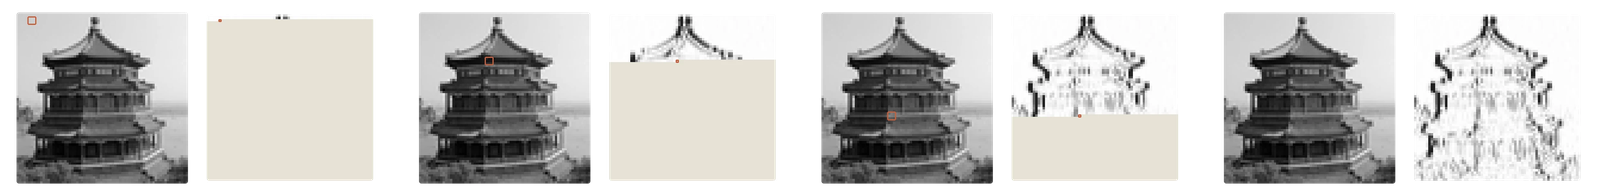



**Hỏi nhanh.** Ta muốn một kernel $2\times 2$ cho số dương với cửa sổ nét chéo $\begin{bmatrix}1&0\\0&1\end{bmatrix}$, nhưng cho 0 với mọi vùng nền đều màu $\begin{bmatrix}c&c\\c&c\end{bmatrix}$. Chọn kernel nào?

- A. $\begin{bmatrix}1&0\\0&1\end{bmatrix}$
- B. $\begin{bmatrix}1&-1\\-1&1\end{bmatrix}$
- C. $\begin{bmatrix}0&1\\1&0\end{bmatrix}$
- D. $\begin{bmatrix}1&1\\1&1\end{bmatrix}$

<details><summary>Đáp án</summary>

B. $\begin{bmatrix}1&-1\\-1&1\end{bmatrix}$

Kernel đúng cho $1 + 1 = 2$ với nét chéo, và cho $c(1 - 1 - 1 + 1) = 0$ với nền đều, vì tổng các trọng số bằng 0. Kernel giống hệt nét chéo cũng cho 2, nhưng với nền đều lại cho $2c$, nên vùng sáng trông như có nét. Kernel chéo phụ cho 0 với chính nét cần tìm. Kernel toàn 1 chỉ đo tổng độ sáng, nên phản ứng mạnh nhất với nền.

</details>

## Padding, stride và dilation thay đổi điều gì?

Padding thêm vành ô quanh ảnh, thường bằng 0. Nó cho kernel đọc cả vùng sát biên và có thể giữ kích thước. Giá trị 0 ở biên là một giả định về bên ngoài ảnh; với ảnh nhỏ, giả định này có ảnh hưởng đáng kể.

Stride là số ô dịch mỗi bước. Stride 2 đọc thưa hơn, giảm chi phí nhưng có thể bỏ sót nét mảnh. Dilation tạo khoảng trống giữa các ô kernel: kernel 3 ô với dilation 2 bao phủ 5 vị trí, dù vẫn chỉ có 3 trọng số theo chiều đó. Kích thước bao phủ hiệu dụng là $d(k-1)+1$.

Ta đếm số vị trí hợp lệ theo một chiều. Chiều dài sau padding là $H+2p$; cửa sổ đầu chiếm $d(k-1)+1$ ô, phần còn lại cho phép dịch từng $s$ ô:

$$H_{\mathrm{out}}=\left\lfloor\frac{H+2p-d(k-1)-1}{s}\right\rfloor+1.$$

Chiều rộng tính tương tự. Công thức giả định mỗi đầu thêm đúng $p$ ô. Với stride 1, muốn giữ kích thước thì cần $2p=d(k-1)$; `padding="same"` của PyTorch tự chọn padding như vậy, và khi $d(k-1)$ lẻ (kernel chẵn) phần dư được thêm ở cuối. Ví dụ $H=7$, $k=3$, $p=1$, $s=2$, $d=1$ cho $\lfloor6/2\rfloor+1=4$. Các vị trí bắt đầu là 0, 2, 4, 6 trên ảnh đã thêm vành, không phải $7/2$ làm tròn tùy ý. Vài trường hợp hay gặp: ảnh $32 \times 32$, kernel 5, không padding ra $28 \times 28$; giữ $64 \times 64$ với kernel 3 cần $p = 1$; kernel 3 với dilation 2 trên 32 ô ra 28.

In [ ]:
def output_size(size, kernel_size, padding=0, stride=1, dilation=1):
    covered = dilation * (kernel_size - 1) + 1
    return (size + 2 * padding - covered) // stride + 1

print(output_size(7, 3, padding=1, stride=2))
print(output_size(7, 3, dilation=2))

4
3


Dòng thứ hai có dilation 2, nên kernel phủ 5 ô, còn 3 vị trí hợp lệ trên chiều dài 7. Tăng dilation không tăng số tham số của kernel nhưng đổi những điểm ảnh được đọc. Xếp chồng nhiều lớp cùng dilation 2 thì có những pixel không bao giờ được đọc, để lại lưới lỗ; đổi dilation giữa các lớp hoặc ghép nhiều dilation song song, như ASPP trong DeepLab, vừa lấp lỗ vừa nhìn ngữ cảnh ở nhiều cỡ. Tăng stride từ 1 lên 2 giữ nguyên số tham số nhưng đầu ra còn khoảng một phần tư số ô.



**Hỏi nhanh.** Ảnh dài 8 ô, kernel 3, padding 0, stride 2, dilation 1. Đầu ra dài bao nhiêu?

- A. 2
- B. 3
- C. 4
- D. 6

<details><summary>Đáp án</summary>

B. 3

Công thức cho $\lfloor(8 - 3)/2\rfloor + 1 = 3$: các vị trí bắt đầu là 0, 2, 4. Bắt đầu ở 6 thì kernel cần ô 6, 7, 8, vượt ra ngoài biên. Ra 4 là lấy $8/2$, quên phần kernel chiếm chỗ. Ra 6 là kết quả của stride 1. Ra 2 là $\lfloor 5/2\rfloor$, quên cộng 1 cho vị trí đầu tiên.

</details>

**Hỏi nhanh.** Conv có kernel 3, dilation 2, stride 1. Padding đối xứng bằng bao nhiêu thì giữ nguyên chiều dài đầu vào?

- A. 1
- B. 2
- C. 3
- D. 4

<details><summary>Đáp án</summary>

B. 2

Kernel phủ $d(k - 1) + 1 = 5$ ô, nên cần $2p = d(k - 1) = 4$, tức $p = 2$. Padding 1 là con số quen thuộc của kernel 3 thường, quên rằng dilation làm vùng phủ giãn ra. Padding 3 là lấy nửa của 5 rồi làm tròn lên, nên đầu ra dài thêm 2 ô. Padding 4 là đặt cả 4 ô thiếu vào mỗi đầu, nên đầu ra dài thêm 4 ô.

</details>

## Từ một bảng sang nhiều kênh

Một ảnh RGB có ba giá trị tại mỗi tọa độ. Một kernel cho **một kênh đầu ra** phải đọc cả ba kênh đầu vào, cộng kết quả rồi cộng một bias. Muốn tám kiểu bộ dò thì dùng tám kernel độc lập.

| Đại lượng | Shape theo PyTorch |
|---|---|
| Batch ảnh | `(N, C_in, H, W)` |
| Trọng số convolution thông thường | `(C_out, C_in, k_h, k_w)` |
| Bias | `(C_out,)` |
| Feature map | `(N, C_out, H_out, W_out)` |

$N$ là số ảnh, không phải số kênh. Với `groups=1`, số tham số có bias bằng $C_{\mathrm{out}}(C_{\mathrm{in}}k_hk_w+1)$. Một lớp RGB → 8 kênh, kernel $3\times3$ có $8(3\cdot9+1)=224$ tham số, dù ảnh lớn hay nhỏ. Chi phí tính vẫn tăng theo số vị trí đầu ra; ít tham số không có nghĩa là chạy miễn phí. Tương tự, `nn.Conv2d(3, 16, 3)` có $16(27 + 1) = 448$ tham số, `nn.Conv2d(3, 64, 3)` có $64 \cdot 28 = 1792$, và `nn.Conv2d(3, 16, kernel_size=5).weight` có shape `(16, 3, 5, 5)`.

Kernel $1 \times 1$ không nhìn hàng xóm mà chỉ trộn kênh tại từng vị trí: khối $28 \times 28 \times 256$ qua 64 bộ lọc $1 \times 1$ thành $28 \times 28 \times 64$. Tích chập theo chiều sâu (depthwise, `groups` bằng số kênh) làm ngược lại: mỗi kênh một kernel riêng, trộn không gian trong từng kênh mà không trộn giữa các kênh; ghép depthwise với $1 \times 1$ là khối quen thuộc của MobileNet, ConvNeXt.



Đối chiếu bảng tính tay với thư viện trước, rồi xem shape của một lớp nhiều kênh:

In [ ]:
import torch
from torch import nn

torch.set_num_threads(1)
x = torch.tensor(image, dtype=torch.float32)[None, None]
layer = nn.Conv2d(1, 1, kernel_size=2, bias=False)
with torch.no_grad():
    layer.weight.copy_(torch.tensor(kernel, dtype=torch.float32)[None, None])
    y = layer(x)
print(tuple(y.shape))
print(np.allclose(y[0, 0].numpy(), feature_map))

rgb_layer = nn.Conv2d(3, 8, 3, padding=1)
print(sum(parameter.numel() for parameter in rgb_layer.parameters()))
print(tuple(rgb_layer(torch.zeros(2, 3, 7, 7)).shape))

(1, 1, 2, 2)
True
224
(2, 8, 7, 7)


`True` xác nhận ta và thư viện dùng cùng quy ước. Shape cuối giữ $7\times7$ vì kernel 3, padding 1, stride 1. Hai ảnh cùng chạy qua tám bộ lọc, nên đầu ra có hai ảnh, tám kênh.

**Hỏi nhanh.** `nn.Conv2d(16, 32, kernel_size=(3, 5))` có `weight.shape` là gì?

- A. `(16, 32, 3, 5)`
- B. `(32, 3, 5)`
- C. `(32, 16, 3, 5)`
- D. `(32, 16, 5, 3)`

<details><summary>Đáp án</summary>

C. `(32, 16, 3, 5)`

Trục đầu là số kernel, tức $C_{\mathrm{out}} = 32$. Mỗi kernel đọc đủ 16 kênh vào, cao 3, rộng 5. `(16, 32, 3, 5)` là chép theo thứ tự đối số của hàm, nhưng trọng số lưu kênh ra trước, kênh vào sau, giống `nn.Linear`. `(32, 3, 5)` là quên rằng mỗi kernel đọc mọi kênh vào. `(32, 16, 5, 3)` là đảo chiều cao và chiều rộng, vì `kernel_size=(3, 5)` theo thứ tự $(k_h, k_w)$.

</details>

**Hỏi nhanh.** Lớp `nn.Conv2d(3, 8, 3, padding=1)` chạy trên ảnh $7\times 7$, rồi chạy trên ảnh $70\times 70$. Số tham số và số phép nhân thay đổi thế nào?

- A. Tham số vẫn là 224, phép nhân tăng 100 lần
- B. Tham số vẫn là 224, phép nhân cũng giữ nguyên
- C. Tham số tăng 100 lần, phép nhân tăng 100 lần
- D. Tham số tăng 10 lần, phép nhân tăng 10 lần

<details><summary>Đáp án</summary>

A. Tham số vẫn là 224, phép nhân tăng 100 lần

Số tham số chỉ phụ thuộc vào $C_{\mathrm{in}}$, $C_{\mathrm{out}}$ và $k$. Padding 1 giữ nguyên kích thước, và mỗi ô đầu ra của mỗi kênh cần $3\cdot 9 = 27$ phép nhân. Vậy số phép nhân là $49\cdot 8\cdot 27 = 10\,584$, rồi $4900\cdot 8\cdot 27 = 1\,058\,400$, gấp 100 lần vì số vị trí tăng theo bình phương cạnh. Nghĩ “ít tham số thì chạy rẻ” thì sẽ chọn phép nhân giữ nguyên. Tính theo cạnh ảnh thay vì diện tích thì ra hệ số 10.

</details>

## Pooling giữ điều gì, mất điều gì?

Sau khi biết một vùng có nét, đôi khi ta không cần vị trí chính xác từng ô. Max pooling lấy giá trị lớn nhất trong cửa sổ; average pooling lấy trung bình. Đây là phép tổng hợp cố định, không có trọng số cần học. Trên feature map $\begin{bmatrix}3&8\\2&1\end{bmatrix}$, max pooling $2\times2$ ra 8, average pooling ra $14/4=3.5$. Khi cửa sổ phủ cả feature map, ta có global pooling: mỗi kênh chỉ còn một số. Global max trả lời “mẫu có xuất hiện ở đâu đó không”; global average đo mẫu phủ nhiều hay ít. `MaxPool2d(2)` trên $7 \times 7$ ra $3 \times 3$ vì hàng, cột lẻ cuối bị bỏ; `ceil_mode=True` giữ cửa sổ thiếu nên ra $4 \times 4$. Thay pooling bằng tích chập stride 2 cũng thu nhỏ map, nhưng cách gộp được học thay vì cố định.



In [ ]:
print(nn.MaxPool2d(2)(y).flatten().tolist())
print(nn.AvgPool2d(2)(y).flatten().tolist())
left = torch.tensor([[[[0., 4., 0., 0.]]]])
right = torch.tensor([[[[0., 0., 4., 0.]]]])
pool = nn.MaxPool2d((1, 2))
print(pool(left).flatten().tolist())
print(pool(right).flatten().tolist())

window = y.detach().clone().requires_grad_(True)
nn.MaxPool2d(2)(window).sum().backward()
print(window.grad[0, 0].tolist())

[8.0]
[3.5]
[4.0, 0.0]
[0.0, 4.0]
[[0.0, 1.0], [0.0, 0.0]]


Dòng ba và bốn cho thấy dịch một ô có thể đưa đỉnh sang cửa sổ khác. Pooling có thể giảm nhạy với dịch nhỏ **bên trong cùng cửa sổ**, nhưng không tạo bất biến dịch tuyệt đối. Với segmentation, làm mất vị trí như vậy còn phải được bù bằng decoder hoặc nhánh giữ chi tiết.



Dòng cuối là gradient khi lan truyền ngược qua max pooling. Chỉ ô đạt max (ô chứa 8) nhận gradient 1, ba ô kia nhận 0: trong bước học này, chỉ ô thắng truyền tín hiệu về các lớp trước. Average pooling thì chia đều, mỗi ô nhận $1/4$. Khi các cửa sổ chồng nhau, một ô có thể thuộc nhiều cửa sổ và gradient của các cửa sổ ấy được cộng lại.

**Hỏi nhanh.** Max pooling trên một cửa sổ $2\times 2$ chỉ trả về số 8. Từ đó có khôi phục duy nhất được bốn ô ban đầu không?

- A. Có, mỗi ô bằng $8/4 = 2$
- B. Có, nếu biết thêm stride của pooling
- C. Có, nếu biết thêm average pooling của cửa sổ
- D. Không, vì nhiều cửa sổ khác nhau có cùng giá trị lớn nhất

<details><summary>Đáp án</summary>

D. Không, vì nhiều cửa sổ khác nhau có cùng giá trị lớn nhất

Giảm kích thước thì mất thông tin. Chia 8 cho 4 là nhầm max với tổng. Stride chỉ cho biết các cửa sổ nằm ở đâu, không cho biết những giá trị đã bị bỏ. Biết thêm trung bình là 3.5 thì ba ô còn lại có tổng bằng 6, vẫn có vô số cách chia.

</details>

**Hỏi nhanh.** `MaxPool1d(kernel_size=2, stride=1)` trên `[1, 9, 3]` cho ra `[9, 9]`. Lấy tổng đầu ra rồi gọi `backward()`. Gradient về đầu vào là gì?

- A. `[0.5, 1, 0.5]`
- B. `[0, 9, 0]`
- C. `[0, 1, 0]`
- D. `[0, 2, 0]`

<details><summary>Đáp án</summary>

D. `[0, 2, 0]`

Ô 9 thắng ở cả hai cửa sổ chồng lên nhau, mỗi cửa sổ gửi về gradient 1, nên tổng là 2. Ô 1 và ô 3 không thắng cửa sổ nào. `[0, 1, 0]` là quên cộng gradient của hai cửa sổ. `[0.5, 1, 0.5]` là gradient của average pooling với cùng cấu hình. `[0, 9, 0]` là nhầm giá trị được chọn với gradient.

</details>

## Receptive field: một ô đã nhìn xa đến đâu?

Vùng tiếp nhận (receptive field) là vùng đầu vào có thể ảnh hưởng đến một ô ở lớp đang xét. Hai kernel $3\times3$ stride 1 cho vùng $5\times5$, vì ba ô cạnh nhau ở lớp thứ nhất có các vùng nhìn chồng lấn. Đây là vùng **có thể** ảnh hưởng theo cấu trúc; trọng số hoặc ReLU có thể làm ảnh hưởng thực tế nhỏ hơn.

Để tính chuỗi lớp, giữ hai số: $r$ là chiều dài vùng nhìn và $j$ là khoảng cách trên ảnh gốc giữa hai ô đầu ra kề nhau. Bắt đầu $r=1$, $j=1$. Với lớp kernel $k$, dilation $d$, stride $s$, cập nhật:

$$r_{\mathrm{mới}}=r_{\mathrm{cũ}}+(k-1)d\,j_{\mathrm{cũ}},\qquad j_{\mathrm{mới}}=s\,j_{\mathrm{cũ}}.$$

Một conv 3, pool 2 stride 2, rồi conv 3 cho $r:1\to3\to4\to8$, $j:1\to1\to2\to2$. Conv cuối đọc ba ô cách nhau hai ô trên ảnh gốc, nên thêm 4 vào vùng nhìn. Công thức đo độ rộng; muốn biết vị trí chính xác ở biên còn phải theo dõi padding. Ba lớp $3 \times 3$ stride 1 cho $7 \times 7$; nếu lớp đầu có stride 2 thì $j$ thành 2 và ba lớp cho $11 \times 11$. Kernel $1 \times 1$ không làm vùng nhìn rộng thêm.



Xếp chồng kernel nhỏ là cách thường dùng để mở vùng nhìn. Hai lớp $3\times3$ nhìn $5\times5$ như một lớp $5\times5$, nhưng mỗi cặp kênh vào–ra chỉ cần $2\cdot9=18$ trọng số thay vì 25, và có thêm một activation ở giữa. Vì thế các họ mạng như VGG, ResNet chủ yếu dùng kernel $3\times3$.

Vùng nhìn lớn dần cũng giải thích vì sao feature map khác nhau theo độ sâu. Lớp đầu chỉ nhìn vài pixel nên phản ứng với cạnh, nét, chỗ đổi màu; feature map của nó còn giống ảnh gốc đã qua bộ lọc. Sau vài lần stride hoặc pooling, mỗi ô nhìn một vùng rộng, map nhỏ và thô đi, phản ứng với tổ hợp lớn hơn như góc, vân, bộ phận của vật. Cấu trúc cho phép thứ bậc ấy xuất hiện; chính huấn luyện mới tạo ra nó.

**Hỏi nhanh.** Một conv kernel 3 stride 2, tiếp theo là một conv kernel 3 stride 1, cả hai có dilation 1. Một ô ở lớp thứ hai nhìn bao nhiêu ô đầu vào theo mỗi chiều?

- A. 5
- B. 6
- C. 7
- D. 9

<details><summary>Đáp án</summary>

C. 7

Lớp đầu cho $r = 3$, $j = 2$. Lớp thứ hai thêm $(3 - 1)\cdot 2 = 4$, nên $r = 7$. Ra 5 là bỏ qua stride, như hai conv stride 1. Ra 6 là cộng $3 + 3$, quên rằng hai cửa sổ liền nhau dùng chung ô. Ra 9 là nhân $3\cdot 3$, như thể vùng nhìn nhân lên qua từng lớp.

</details>

## Giả định và ứng dụng

Convolution giả định các mẫu cục bộ hữu ích và cùng mẫu có thể xuất hiện ở nhiều vị trí. Điều này hợp với cạnh, góc, vân; chưa đủ để tự hiểu quan hệ “quyển sách bên trái cửa sổ”. Ta cần nhiều lớp để ghép chi tiết thành cấu trúc, hoặc cơ chế khác để trao đổi thông tin xa như attention ở bài 5.4.

Với stride 1, dịch ảnh đi một ô thì feature map dịch theo đúng một ô, các giá trị giữ nguyên trừ vùng sát biên. Tính chất này gọi là đồng biến với phép dịch (translation equivariance). Bất biến, tức đầu ra không đổi khi ảnh dịch, chỉ xuất hiện khi về sau có phép gộp vị trí như global pooling; pooling cục bộ chỉ giảm nhạy với dịch nhỏ và vỡ khi đỉnh qua ranh giới cửa sổ, như cặp `[4.0, 0.0]` và `[0.0, 4.0]` ở trên. CNN cũng không tự bất biến với xoay, đổi tỉ lệ hay đổi ánh sáng.



Giả định “mẫu có thể ở bất kỳ đâu” yếu đi khi ảnh đã được căn chỉnh, ví dụ ảnh thẻ mà mắt luôn ở cùng một chỗ. Ngược lại, khi đề cần tọa độ tuyệt đối như vị trí một nguồn hay một keypoint, global pooling xóa đúng thông tin cần tìm; head phải đọc feature map còn chiều không gian, hoặc input được thêm hai kênh chứa tọa độ $x, y$ của từng ô.

Quay lại nét phấn: bộ dò cục bộ giúp tái sử dụng tri thức khi nét dịch chỗ. Ta vẫn phải kiểm ảnh của nhiều học sinh, nhiều camera, nhiều độ sáng. Nếu dữ liệu train chỉ có nét ở giữa ảnh, bộ lọc dùng chung chưa bảo đảm classifier cuối không học thói quen “nét luôn ở giữa”. Chia sẻ trọng số là một giả định: bớt tham số nên giảm variance, đổi lại thêm bias khi giả định sai. Lớp kết nối đầy đủ cùng số đơn vị vào, ra biểu diễn được mọi thứ tích chập làm được, chỉ cần nhiều dữ liệu hơn hẳn để học; khi ảnh đã căn chỉnh sẵn, vật luôn cùng cỡ và cùng chỗ, lợi thế của tích chập nhỏ đi.

**Hỏi nhanh.** Một bộ dò nét đã học tốt trên những ảnh chỉ có nét dựng đứng, ở đủ mọi vị trí. Ảnh test bị xoay $90^\circ$ nên nét thành nằm ngang. Nhiều khả năng chuyện gì xảy ra?

- A. Nhận kém, vì kernel nét dọc phản ứng yếu với nét ngang
- B. Nhận kém, vì xoay làm đổi shape `(N, C, H, W)`
- C. Vẫn nhận tốt, vì dùng chung kernel ở mọi vị trí
- D. Vẫn nhận tốt, nếu thêm padding cho ảnh đã xoay

<details><summary>Đáp án</summary>

A. Nhận kém, vì kernel nét dọc phản ứng yếu với nét ngang

Dùng chung kernel chỉ giúp khi mẫu dịch chỗ. Xoay thì làm đổi chính mẫu cục bộ mà kernel đang so. Muốn bền với phép xoay, cần dữ liệu hoặc augmentation có xoay (bài 5.3). Ảnh vuông xoay $90^\circ$ vẫn giữ nguyên shape. Padding chỉ thêm một vành quanh ảnh, không đổi được hướng của nét.

</details>

## Khi đi thi

- **Chạy batch giả và in shape từng khối.** Đưa `torch.zeros(2, C, H, W)` qua model trong vài giây là biết `Linear` cuối cần bao nhiêu đặc trưng, thay vì vỡ sau khi đã nạp xong dữ liệu.
- **Đổi trục bằng `permute`, rồi kiểm một pixel.** Dữ liệu đề hay ở dạng `(H, W, C)` (ảnh, lưới đo); `Conv2d` cần `(N, C, H, W)`. So giá trị một pixel trước và sau khi đổi.
- **Chọn số lần downsample theo chi tiết nhỏ nhất.** Đo cỡ vật hoặc nét nhỏ nhất trong dữ liệu; bước nhảy $j$ lớn hơn nó nhiều thì chi tiết dễ mất trước khi head đọc tới.
- **Đề cần tọa độ hay mask thì giữ chiều không gian.** Global pooling hợp với nhãn cho cả ảnh; tọa độ, keypoint, mask cần feature map còn vị trí, heatmap hoặc decoder.
- **Ước lượng thời gian ở kích thước thật.** Phép tính tỉ lệ với số vị trí đầu ra: cạnh ảnh gấp đôi thì phép tính gấp bốn. Đo một epoch nhỏ trên phần cứng của đề trước khi chọn độ phân giải.

## Tóm tắt

Convolution đọc cửa sổ cục bộ bằng trọng số dùng chung, nên số tham số không phụ thuộc kích thước ảnh, còn chi phí tính thì có. Padding, stride và dilation quyết định vị trí đọc và kích thước đầu ra. Pooling tổng hợp mà không học trọng số, đổi độ chính xác vị trí lấy biểu diễn gọn; khi lan truyền ngược, max pooling chỉ gửi gradient về ô thắng. Receptive field tăng qua nhiều lớp, và xếp chồng $3\times3$ mở vùng nhìn với ít trọng số. Convolution đồng biến với phép dịch nhưng không tự bất biến với xoay hay tỉ lệ; vùng nhìn lớn và hiểu ngữ nghĩa là hai việc cần kiểm riêng.

## Kiểm tra cuối bài

**Câu 1.** Ảnh $28\times 28$ đi qua 5 lớp conv $3\times 3$ stride 1 nối tiếp nhau. Kích thước cuối cùng khi không có padding, và khi mọi lớp có `padding=1`, lần lượt là bao nhiêu?

- A. $23\times 23$ và $28\times 28$
- B. $18\times 18$ và $28\times 28$
- C. $13\times 13$ và $28\times 28$
- D. $18\times 18$ và $38\times 38$

<details><summary>Đáp án</summary>

B. $18\times 18$ và $28\times 28$

Không có padding, mỗi lớp mất $k - 1 = 2$ ô ở mỗi chiều: $28 - 5\cdot 2 = 18$. Padding 1 thêm một vành vừa đủ bù lại 2 ô ấy, nên giữ nguyên 28. Trừ 1 mỗi lớp là nhầm $k - 1$ thành 1. Trừ 3 mỗi lớp là nhầm thành $k$. Ra 38 là cộng thêm padding mà quên rằng kernel lấy lại đúng phần ấy.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 202](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=74)

</details>

**Câu 2.** Ảnh $6\times 6$, kernel $3\times 3$, không padding, stride 1 cho đầu ra $4\times 4$. Giữ nguyên kernel, cấu hình nào cho đầu ra đúng $3\times 3$?

- A. Stride 1, padding 1
- B. Stride 2, padding 0
- C. Stride 2, padding 1
- D. Stride 3, padding 0

<details><summary>Đáp án</summary>

C. Stride 2, padding 1

$\lfloor(6 + 2 - 3)/2\rfloor + 1 = 3$. Ảnh sau khi padding dài 8, các cửa sổ bắt đầu ở 0, 2, 4, nên hàng và cột padding cuối cùng không bao giờ được đọc. Stride 1 với padding 1 giữ nguyên $6\times 6$, còn lớn hơn trước. Stride 2 không padding cho $\lfloor 3/2\rfloor + 1 = 2$, giảm quá tay. Stride 3 cũng cho 2.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.2(a)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=6)

</details>

**Câu 3.** Trên ảnh $32\times 32$, một kênh vào, một kênh ra, stride 1, bỏ qua bias, so hai lớp: conv kernel 3, dilation 2, padding 2, và conv kernel 5, padding 2. Nhận xét nào đúng?

- A. Kernel giãn cho ra $34\times 34$, cả hai đều có 25 trọng số
- B. Kernel giãn cho ra $34\times 34$, một bên 9, một bên 25 trọng số
- C. Cả hai cùng ra $32\times 32$, đều có 25 trọng số
- D. Cả hai cùng ra $32\times 32$, một bên 9, một bên 25 trọng số

<details><summary>Đáp án</summary>

D. Cả hai cùng ra $32\times 32$, một bên 9, một bên 25 trọng số

Kernel giãn phủ $2\cdot 2 + 1 = 5$ ô, nên kích thước tính như kernel 5: $32 + 4 - 5 + 1 = 32$. Nhưng nó chỉ đọc 9 ô cách quãng trong vùng $5\times 5$, nên chỉ có 9 trọng số. $34\times 34$ là tính như kernel 3 thường với padding 2, quên dilation. 25 trọng số là nhầm vùng phủ với số trọng số.

</details>

**Câu 4.** Model nhận batch `(8, 3, 32, 32)`:
```py
nn.Sequential(
    nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(IN, 10))
```
`IN` phải bằng bao nhiêu?

- A. $32\cdot 32\cdot 32 = 32\,768$
- B. $32\cdot 16\cdot 16 = 8192$
- C. $32\cdot 8\cdot 8 = 2048$
- D. $32\cdot 4\cdot 4 = 512$

<details><summary>Đáp án</summary>

C. $32\cdot 8\cdot 8 = 2048$

Conv với `padding=1` giữ nguyên kích thước, còn mỗi `MaxPool2d(2)` chia đôi: $32 \to 16 \to 8$, và số kênh cuối là 32. 32 768 là quên rằng pooling làm giảm kích thước không gian. 8192 là chỉ tính một lần pooling. 512 là chia đôi thêm một lần nữa, như thể một lớp conv cũng làm giảm kích thước. Sai `IN` sẽ hiện thành lỗi nhân ma trận ngay ở batch đầu tiên; chạy một batch giả và in shape trước `Linear` là thấy ngay.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 11](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=2)

</details>

**Câu 5.** Một conv 1D có một bộ lọc, và $z_j$ lớn nghĩa là có mẫu cần tìm ở vị trí $j$. Mạng A cho ra $\sigma(\max_j z_j)$, mạng B cho ra $\sigma(\min_j z_j)$. Đầu ra cao nghĩa là “mẫu có ở mọi vị trí” ở mạng nào, và nghĩa là “mẫu có ở ít nhất một vị trí” ở mạng nào?

- A. A rồi B
- B. B rồi A
- C. A ở cả hai
- D. B ở cả hai

<details><summary>Đáp án</summary>

B. B rồi A

Min cao chỉ khi mọi $z_j$ đều cao, tức mẫu có ở mọi vị trí. Max cao thì chỉ cần một $z_j$ cao. Dễ gán A cho “mọi vị trí” vì max đọc qua toàn bộ ảnh, nhưng đọc qua toàn bộ không có nghĩa là đòi hỏi toàn bộ. Muốn đo “có ở ít nhất một nửa số vị trí” thì cả hai đều không đo được; phải dùng một phép gộp khác, chẳng hạn tỉ lệ các $z_j$ vượt ngưỡng.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q8](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=21)

</details>

**Câu 6.** Hai lớp conv $3\times 3$, stride 1, không padding. Xét ô $(0, 0)$ của lớp thứ hai, với chỉ số tính từ 0. Nhận xét nào đúng?

- A. Đổi pixel đầu vào $(4, 4)$ có thể làm ô này thay đổi
- B. Chỉ các pixel trong khối $3\times 3$ đầu tiên ảnh hưởng tới ô này
- C. Đổi pixel đầu vào $(5, 5)$ cũng có thể làm ô này thay đổi
- D. Mọi pixel đều ảnh hưởng, vì hai lớp nối tiếp nhau

<details><summary>Đáp án</summary>

A. Đổi pixel đầu vào $(4, 4)$ có thể làm ô này thay đổi

Ô $(0, 0)$ của lớp hai đọc các ô ở hàng 0 tới 2, cột 0 tới 2 của lớp một. Mỗi ô ấy lại nhìn thêm hai hàng, hai cột, nên vùng nhìn là hàng 0 tới 4, cột 0 tới 4. Khối $3\times 3$ chỉ là vùng nhìn của một lớp. $(5, 5)$ là đếm $3 + 3 = 6$ ô, quên rằng các cửa sổ chồng lên nhau. Convolution nối cục bộ, khác với lớp `Linear`. Chữ “có thể” là cần thiết, vì trọng số bằng 0 hay ReLU tắt có thể khiến ảnh hưởng thực tế bằng 0.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 214](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=78)

</details>

**Câu 7.** Một đội thay một conv $7\times 7$, 64 kênh vào, 64 kênh ra, bằng ba conv $3\times 3$ từ 64 sang 64 nối tiếp, stride 1, có ReLU ở giữa. So với lớp cũ, bỏ qua bias, điều nào đúng?

- A. Vùng nhìn chỉ còn $3\times 3$, và ít trọng số hơn
- B. Vùng nhìn thành $9\times 9$, và ít trọng số hơn
- C. Vùng nhìn vẫn là $7\times 7$, và ít trọng số hơn
- D. Vùng nhìn vẫn là $7\times 7$, nhưng nhiều trọng số hơn

<details><summary>Đáp án</summary>

C. Vùng nhìn vẫn là $7\times 7$, và ít trọng số hơn

Ba lớp $3\times 3$ cho $r = 1 + 2 + 2 + 2 = 7$. Về trọng số, $3\cdot 9\cdot 64^2 = 110\,592$ so với $49\cdot 64^2 = 200\,704$, chỉ khoảng 55%, lại còn có thêm hai ReLU. $3\times 3$ là vùng nhìn của một lớp. $9\times 9$ là nhân $3\cdot 3$ thay vì cộng. “Nhiều hơn” là đếm ba lớp mà quên rằng mỗi lớp nhỏ hơn hẳn.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 215](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=78)

</details>

**Câu 8.** Đưa một ảnh qua một CNN pretrained, lấy feature map ở năm lớp có độ sâu khác nhau, rồi xáo thứ tự. Dấu hiệu nào giúp xếp lại theo độ sâu đáng tin nhất?

- A. Map sáng hơn, tức giá trị lớn hơn, là lớp sâu hơn
- B. Map lớn, còn thấy được đường viền của vật, là lớp nông
- C. Map càng sắc nét, càng nhiều chi tiết thì càng là lớp sâu
- D. Không xếp được, vì map không giữ gì của ảnh

<details><summary>Đáp án</summary>

B. Map lớn, còn thấy được đường viền của vật, là lớp nông

Lớp nông có vùng nhìn nhỏ, chưa qua nhiều stride hay pooling, nên map còn lớn và phản ứng với các cạnh, trông như ảnh đã qua bộ lọc. Lớp sâu có vùng nhìn rộng, map nhỏ và thô, khó nhận ra vật. Độ lớn của giá trị phụ thuộc chuẩn hóa và activation, không tăng đều theo độ sâu. “Học nhiều hơn nên nét hơn” là đảo ngược chiều: chi tiết không gian giảm dần qua các lớp. Map nào cũng được tính từ ảnh, nên vẫn mang thông tin của ảnh.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Problem 6](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=16)

</details>

**Câu 9.** Mọi ảnh xe đều chụp ngang, cùng cỡ, đầu xe luôn quay sang phải, nên bánh xe, cửa kính, đèn luôn ở gần cùng một chỗ. Bỏ qua chi phí tính toán, dùng chung một bộ kernel cho mọi vị trí có còn là lựa chọn rõ ràng nhất không?

- A. Có, vì không dùng chung thì không học được nét nào
- B. Có, vì dùng chung trọng số tạo ra tính bất biến với phép xoay
- C. Không, vì pooling đã bất biến với phép dịch tuyệt đối
- D. Không hẳn, vì mỗi vùng có thể có bộ lọc riêng của nó

<details><summary>Đáp án</summary>

D. Không hẳn, vì mỗi vùng có thể có bộ lọc riêng của nó

Convolution giả định cùng một mẫu có thể xuất hiện ở bất cứ đâu. Khi vị trí đã cố định, mỗi vùng luôn chứa cùng một loại chi tiết, nên bộ lọc riêng cho vùng bánh xe, vùng cửa kính, tức một lớp nối cục bộ không dùng chung, có thể hợp hơn. Đổi lại là nhiều tham số hơn và cần nhiều dữ liệu hơn. Không dùng chung vẫn học được, như MLP vẫn học. Dùng chung trọng số không tạo ra bất biến với phép xoay, và pooling chỉ làm bớt nhạy với những phép dịch nhỏ.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.4(b)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=8)

</details>

**Câu 10.** Mỗi mẫu là một tensor `(64, 64, 2)`: vector lực $(F_x, F_y)$ đo trên lưới $64\times 64$. Phải dự đoán tọa độ nguồn $(x_s, y_s)$ cùng 100 giá trị cường độ. Một đội dùng các conv stride 1, rồi global average pooling, rồi `Linear` ra 102 số, và lỗi tọa độ rất cao. Thay đổi nào nhắm đúng nguyên nhân?

- A. Đổi global average pooling thành global max pooling
- B. Tăng gấp đôi số kênh của lớp conv cuối
- C. Thêm padding để conv đọc được cả vùng biên
- D. Bỏ global pooling, flatten feature map để còn giữ vị trí

<details><summary>Đáp án</summary>

D. Bỏ global pooling, flatten feature map để còn giữ vị trí

Conv stride 1 dịch theo đầu vào: nguồn dịch chỗ thì feature map dịch theo, còn trung bình toàn cục gần như không đổi, nên head khó đọc ra tọa độ. Flatten feature map, hoặc dự đoán một heatmap, thì giữ lại được vị trí. Thêm hai kênh tọa độ $x$, $y$ vào input cũng là một cách. Global max cũng gộp mất vị trí. Gấp đôi số kênh hay thêm padding không đưa được vị trí trở lại sau phép gộp.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Problem 2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=13)

</details>

## Đọc thêm

- [Dive into Deep Learning — Convolutions for Images](https://d2l.ai/chapter_convolutional-neural-networks/conv-layer.html): phân biệt cross-correlation với convolution, và xem một kernel phát hiện cạnh được học lại từ dữ liệu.
- [PyTorch — Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html): đối chiếu shape, `groups`, `padding="same"` và công thức kích thước khi cấu trúc khác ví dụ.
- [Dumoulin và Visin — A guide to convolution arithmetic for deep learning](https://arxiv.org/abs/1603.07285): hình vẽ từng trường hợp padding, stride, dilation và kích thước đầu ra tương ứng.
- [Dive into Deep Learning — Pooling](https://d2l.ai/chapter_convolutional-neural-networks/pooling.html): xem các phép tổng hợp và vai trò giảm kích thước, rồi tự thử một ảnh có nét mảnh.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0).